# FFT & Crest Factor Calculator
This document presents how I got the crest factors CF and got the datasets for plot generation of some EMG signals taken from an open database:
|  |  |
|--|--|
| URL | https://archive.ics.uci.edu/ml/datasets/EMG+data+for+gestures |
| Title | EMG data for gestures Data Set |
| Requested citation | Supported by the Ministry of Education and Science of the Russian Federation in the framework of megagrant allocation in accordance with the decree of the government of the Russian Federation â„–220, project â„– 14.Y26.31.0022 |

Before beginning to run code, we need to start our jupyter-notebook in the working directory. On UNIX like systems use the following command:
```bash
jupyter notebook --notebook-dir="/absolute/path/to/working/dir"
```

## Setup
Import libraries, set some plot parameters, load data table directories

In [1]:
import pandas as pd
import numpy as np
import scipy as sp
from scipy.fft import fft, fftfreq, fftshift
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm
import seaborn as sns
import itertools as itr
import inspect
import textwrap
from tabulate import tabulate

%matplotlib inline
mpl.rcParams.update(mpl.rcParamsDefault)
sns.set_theme()
sns.set_style("ticks")

cur_path = Path.cwd()
dataset_dir = cur_path / 'datasets'
data_dirs = [i for i in dataset_dir.iterdir() if i.is_dir()]
data_paths = [j for i in range(len(data_dirs)) for j in data_dirs[i].iterdir() if j.is_file()]

csv_fft_length=10000

Define classes and functions that help to manage the data

In [18]:
class Debug:
	def _append_to_table(self, table, var, cl=None):
		if cl == None:
			wrapped_msg = textwrap.fill(str(eval('self.' + var)), 50)
		else:
			wrapped_msg = textwrap.fill(str(eval('self.' + cl + '.' + var)), 50)
		table.append([var.capitalize(), wrapped_msg])

		return table

	def _iterate_class_vars(self, table, variables, cl=None):
		for var in variables:
			if not var.startswith('__') and not var.endswith('__'):
				flag = False
				try:
					flag = inspect.isclass(eval('self.' + type(eval('self.' + var)).__name__))
				except:
					pass
				if flag:
					self._iterate_class_vars(table, list(vars(eval('self.' + var)).keys()), var)
				self._append_to_table(table, var, cl)

	def display(self):
		table=[]
		self._iterate_class_vars(table, list(vars(self).keys()))
		print(tabulate(table, tablefmt='grid'))

class Signal(Debug):
	def __init__(self):
		self.time = np.zeros((0))
		self.sample_sets = np.zeros((0))
		self.sample_class = np.zeros((0))
		self.channel_num = None
		self.sample_period = None
		self.sample_num = None

	def set_signal(self, time, sample_sets, sample_class, sample_period):
		self.time = time
		self.sample_sets = sample_sets
		self.sample_class = sample_class
		self.channel_num = np.shape(self.sample_sets)[0]
		self.sample_period = sample_period
		self.sample_num = np.shape(self.time)[-1]
		super().__init__()

	def to_csv(self, name, headers):
		pd.DataFrame(np.vstack((self.time, self.sample_sets)).transpose()).to_csv(name + ".csv", header=headers, index=False)

class SignalFFT(Debug):
	def __init__(self, freqs=None, spect=None):
		self.freqs = freqs
		self.spect = spect
		super().__init__()

	def set_avg_fft(self, signal):
		self.freqs, self.spect = get_avg_fft(signal)
	
	def to_csv_fft(self, name, headers):
		pd.DataFrame(np.vstack((self.freqs, self.spect)).transpose()).to_csv(name + ".csv", header=headers, index=False)

class SignalFrame(Signal):
	def get_df_from_path(self, path):
		f = open(self.path)
		df = pd.read_csv(self.path, sep="\t")
		return df

	def __init__(self, path, sample_period, time_col=0, channel_col_range=[1,9], class_col=9):		
		self.path = path
		self.df = self.get_df_from_path(self.path)
		arr = self.df.to_numpy().transpose()
		super().__init__()
		self.set_signal(arr[time_col].astype(int), arr[channel_col_range[0]:channel_col_range[1]], arr[class_col].astype(int), sample_period)

def get_fft_spect(signal, iter):
	spect = (2./csv_fft_length) * np.abs(fft(signal.sample_sets[iter], n=csv_fft_length))[:csv_fft_length//2]
	return spect

def get_fft_freqs(signal):
	freqs = fftfreq(csv_fft_length, signal.sample_period)[:csv_fft_length//2]
	return freqs

def get_avg_fft(signal):
	freqs = get_fft_freqs(signal)
	spect_sum = np.zeros((np.shape(freqs)[0],))
	for i in range(0, signal.channel_num):
		spect_sum = get_fft_spect(signal, i) + spect_sum
	spect_avg = spect_sum / signal.channel_num
	return (freqs, spect_avg)

def get_cf(signal):
	cf = np.max(np.abs(signal.sample_sets.flatten()))/np.sqrt(np.mean(np.square(signal.sample_sets.flatten())))
	return cf

def get_peak(signal):
	return np.max(signal.sample_sets)

def plot_vs_time(signal):
	fig, ax = plt.subplots(1, 1, dpi=100, figsize=(20,3))
	colors = iter(cm.twilight(np.linspace(.73, .27, signal.channel_num)))
	for i in range(0, signal.channel_num):
		color=next(colors)
		ax.plot(signal.time, signal.sample_sets[i], c=color, alpha=.7)
	plt.show()

def plot_vs_freqs(signalfft):
	fig, ax = plt.subplots(1, 1, dpi=100, figsize=(20,6))
	ax.plot(signalfft.freqs, signalfft.spect, c='tab:red')
	ax.set_yscale('log')
	ax.set_xscale('log')
	ax.grid()
	plt.show()

def is_valid_data_num(num):
	data_paths_len = len(data_paths)
	if num < 0 or num >= data_paths_len:
		raise ValueError(f"Number must be one of the datasets, in range 0 to {data_paths_len}")

## Test
First let's test our FFT, CF calculations:

We create a function, in this example $$f_1(x) = \sin(2\pi \cdot x \cdot 10) \mathrm{,} \: f_2(x) = \sin(2\pi \cdot x \cdot 50) \mathrm{,} \: f_3(x) = \sin(2\pi \cdot x \cdot 100) \mathrm{,}$$ and we expect it to show int terms of CF: $$CF = \frac{1}{\sqrt{\frac{\int_0^{0.1} f(x)^2 \mathrm{d}x}{0.1}}} = \sqrt{2}$$ and peaks after Fourier transform in $$P = \{10, 50, 100\}$$

In [3]:
em=Signal()
n = 1000000

t = 1./1000
cl = np.zeros((n))
time = np.linspace(0, n, n).astype(int)
signal = np.vstack((np.sin(2 * np.pi * time * t * 10), np.sin(2 * np.pi * time * t * 50), np.sin(2 * np.pi * time * t * 100)))
em.set_signal(time, signal, cl, t)
# em.display()
contents='time\tchannel0\tchannel1\tchannel2\tclass\n'
for i in range(0, em.time.shape[0]):
	contents += str(em.time[i]) + "\t" + str(em.sample_sets[0,i]) + "\t" + str(em.sample_sets[1,i]) + "\t" + str(em.sample_sets[2,i]) + "\t" + str(em.sample_class[i]) + "\n"

fn_set = open("data.txt", "wt")
fn_set.write(contents)
fn_set.close()

In [4]:
t = 1./1000
cemg = SignalFrame(cur_path / "data.txt", t, 0, [1,4], 4)
cemg_sfft = SignalFFT()
cemg_sfft.set_avg_fft(cemg)

CF = 1.4142137721131074


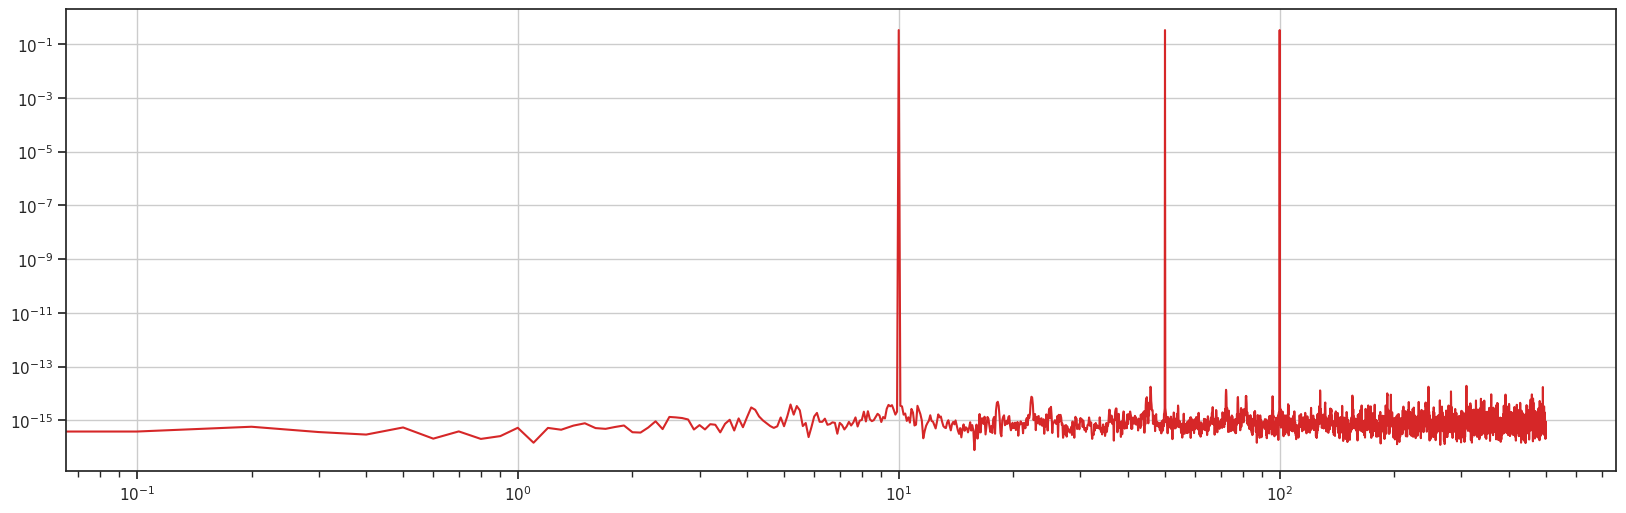

In [5]:
print(f"CF = {get_cf(cemg)}")
plot_vs_freqs(cemg_sfft)

The match of the predicted results lets us check not only the correctness of our functions, but also the reading of dataset files because of the similar structure of data file created in the example with the dataset files

## Calculation
Load our data and concatenate it in one big  (plot with ```plot_vs_time(emg_total_s)``` it or take a glance at it with ```emg_total_s.display()```)

In [6]:
emg_total_s = Signal()
emg_sf = SignalFrame(data_paths[0], 1./1000)
emg_total_s.time = emg_sf.time
emg_total_s.sample_sets = emg_sf.sample_sets
emg_total_s.sample_class = emg_sf.sample_class
for data_path in data_paths:
	emg_sf = SignalFrame(data_path, 1./1000)
	emg_total_s.time = np.hstack((emg_total_s.time, emg_sf.time + emg_total_s.time[-1]))
	emg_total_s.sample_sets = np.hstack((emg_total_s.sample_sets, emg_sf.sample_sets))
	emg_total_s.sample_class = np.hstack((emg_total_s.sample_class, emg_sf.sample_class))
emg_total_s.set_signal(emg_total_s.time, emg_total_s.sample_sets, emg_total_s.sample_class, 1./1000)

In [7]:
# emg_total_s.display()
# plot_vs_time(emg_total_s)
# emg_total_s.to_csv('signal')

Get the FFT of the signal (similarly, plot with ```plot_vs_freq(emg_total_sfft)``` it or take a glance at it with ```emg_total_sfft.display()```)

In [8]:
emg_total_sfft = SignalFFT()
emg_total_sfft.set_avg_fft(emg_total_s)

CF = 6.840961412589475


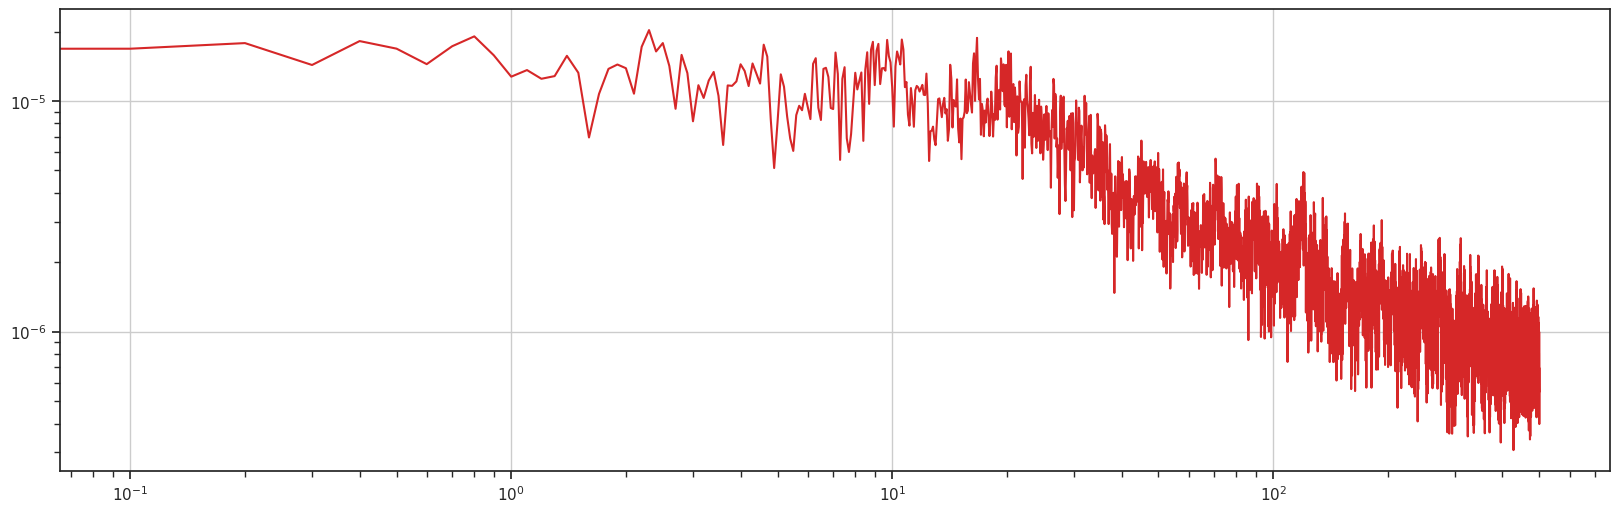

In [9]:
print(f"CF = {get_cf(emg_total_s)}")
# emg_total_sfft.display()
plot_vs_freqs(emg_total_sfft)
emg_total_sfft.to_csv_fft('sfft', ['freqs', 'spect'])

Filter signal for specific gestures and calculate CF & FFT with their noise removed counterparts

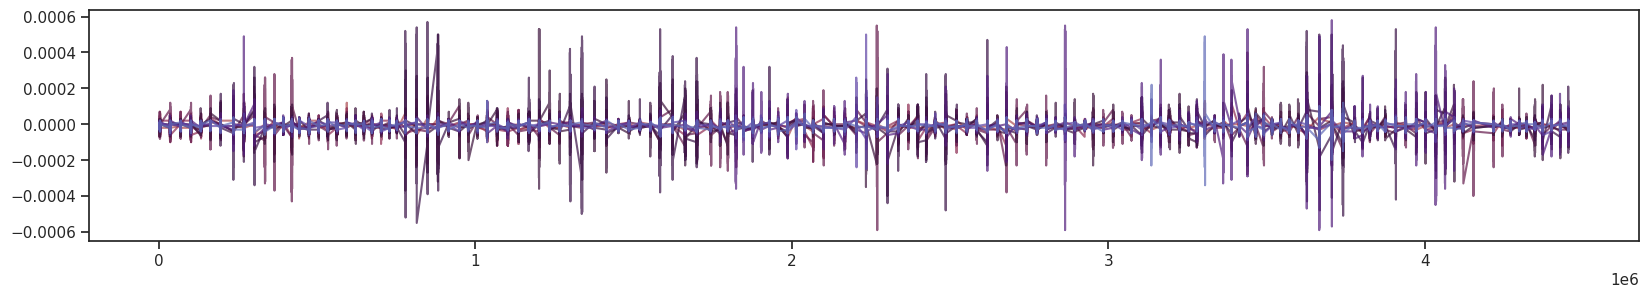

CF = 16.474907033424337


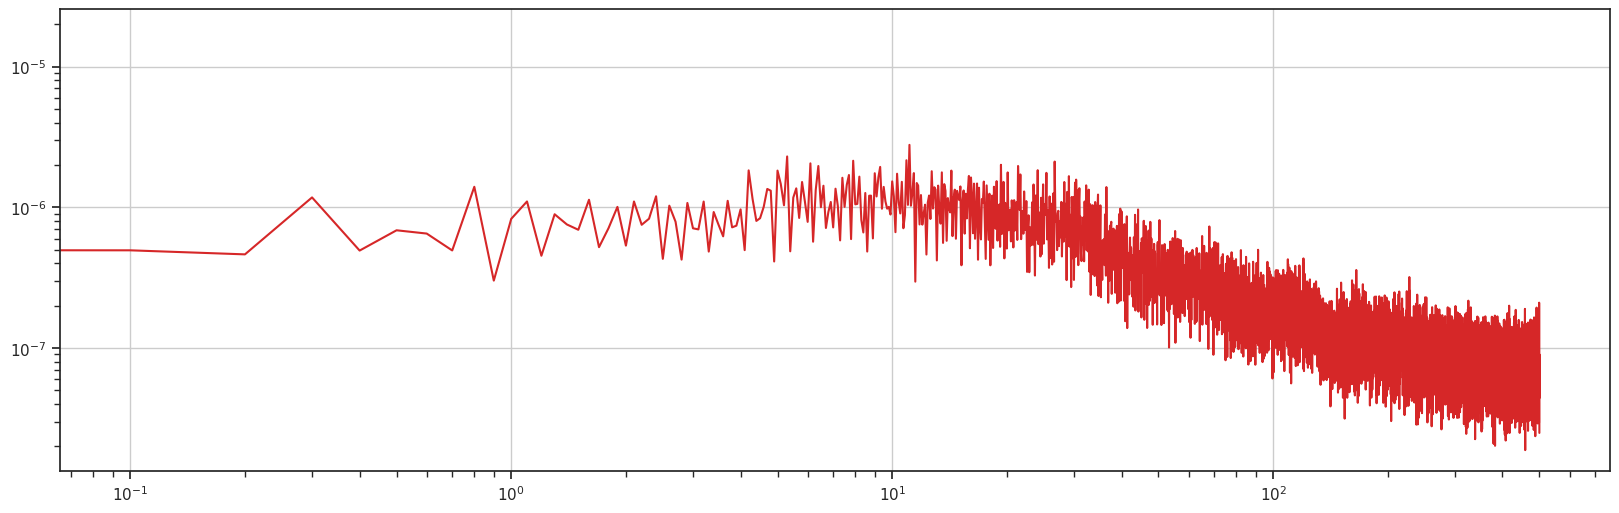

In [10]:
condition0 = emg_total_s.sample_class == 1
condition1 = np.all(np.abs(emg_total_s.sample_sets) < 0.0006, axis=0)
condition = np.logical_and(condition0, condition1)
emg_total_active_noise_s = Signal()
emg_total_active_noise_s.set_signal(emg_total_s.time[condition], emg_total_s.sample_sets[:, condition], emg_total_s.sample_class[condition], emg_total_s.sample_period)
emg_total_active_noise_s.to_csv('noise_s', ['time', 'channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8',])
# emg_total_active_noise_s.display()
plot_vs_time(emg_total_active_noise_s)
emg_total_active_noise_sfft = SignalFFT()
emg_total_active_noise_sfft.set_avg_fft(emg_total_active_noise_s)
print(f"CF = {get_cf(emg_total_active_noise_s)}")
# emg_total_active_noise_sfft.display()
plot_vs_freqs(emg_total_active_noise_sfft)
emg_total_active_noise_sfft.to_csv_fft('noise_sfft', ['freqs', 'spect'])

CF = 4.976177475095663


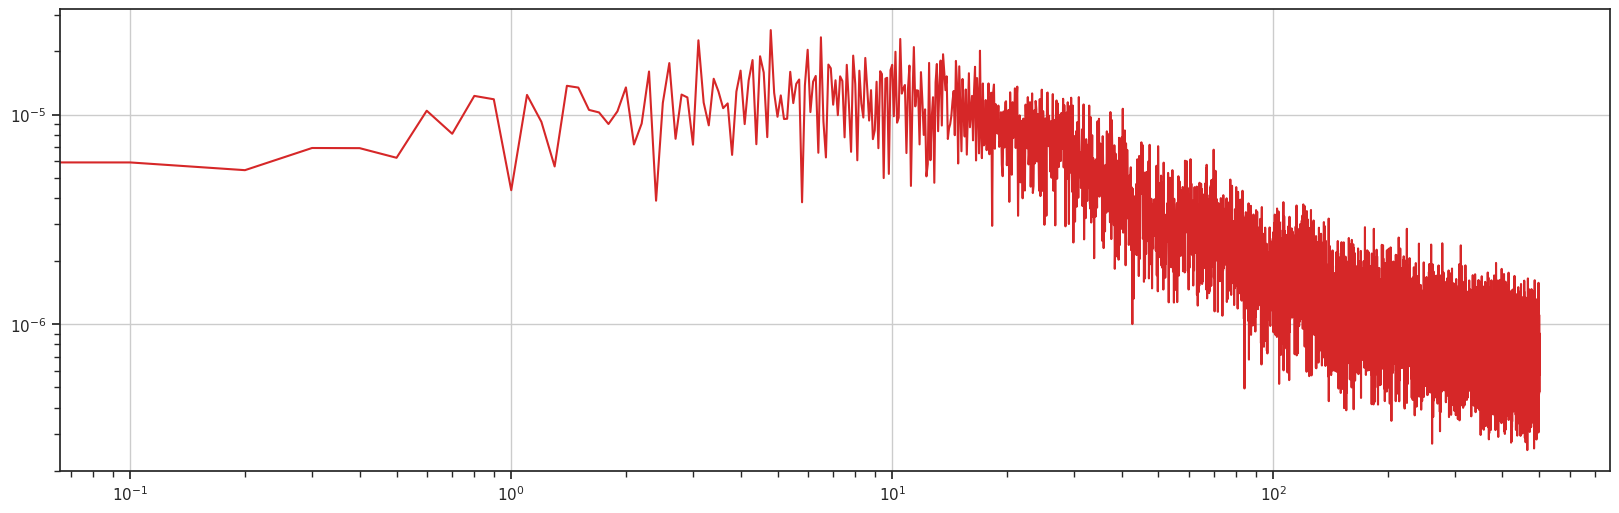

CF = 4.976177475095663


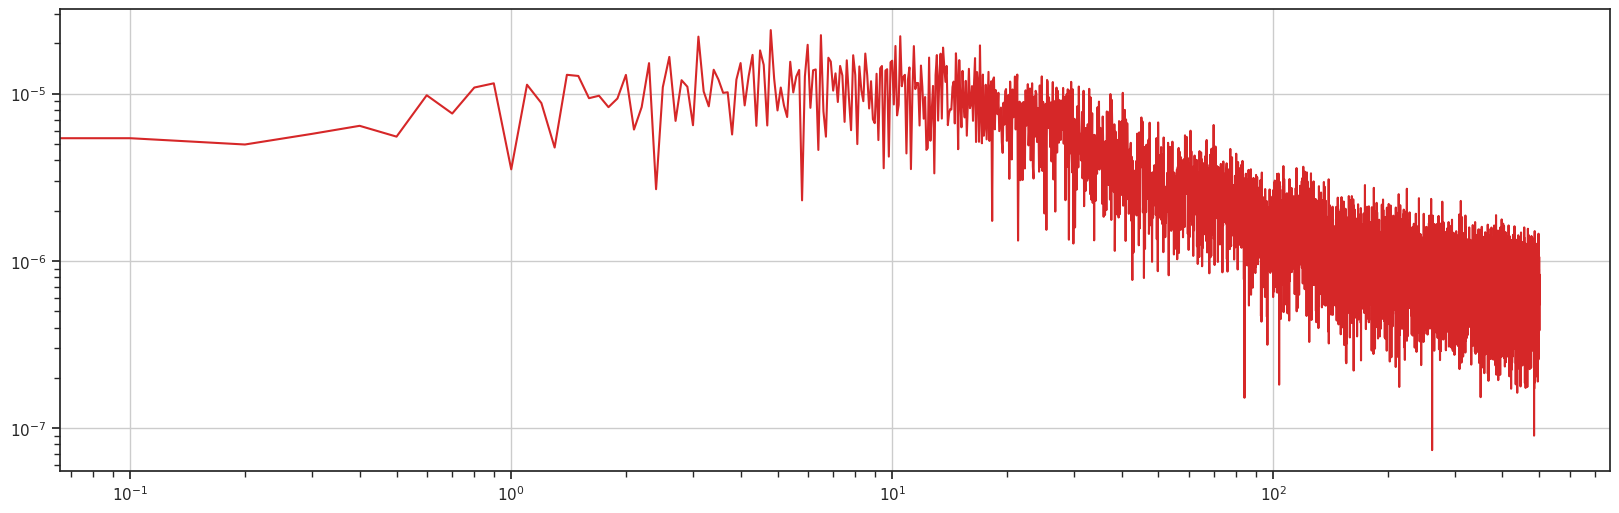

CF = 5.100203854109193


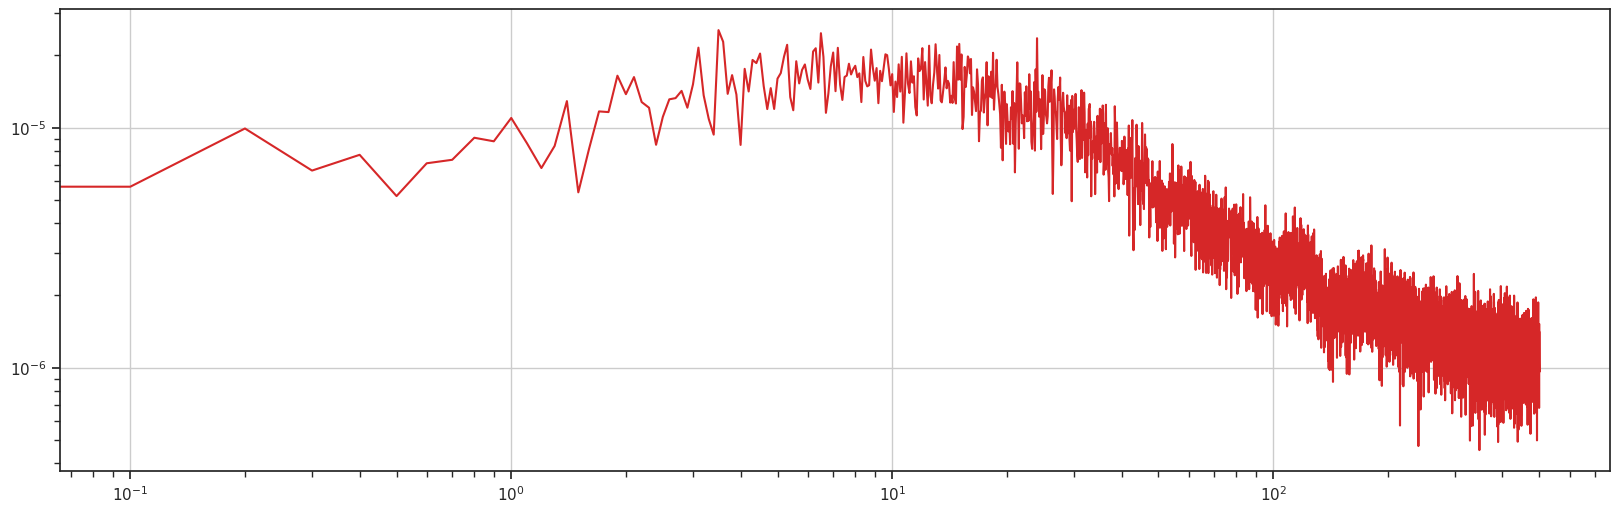

CF = 5.100203854109193


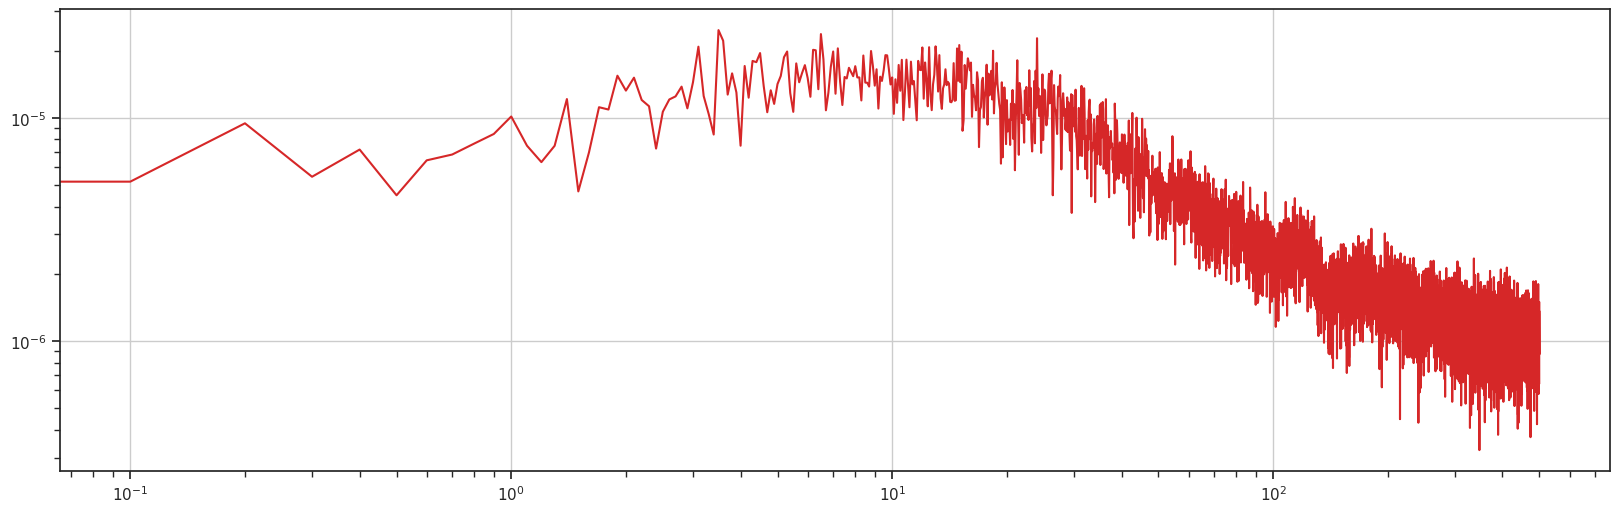

In [11]:
for i, gesture in zip([2, 7], ['fist', 'extended']):
	for j in [0,1]:
		condition = emg_total_s.sample_class == i
		emg_total_active_s = Signal()
		emg_total_active_s.set_signal(emg_total_s.time[condition], emg_total_s.sample_sets[:, condition], emg_total_s.sample_class[condition], emg_total_s.sample_period)
		# emg_total_active_s.display()
		# plot_vs_time(emg_total_active_s)
		emg_total_active_sfft = SignalFFT()
		emg_total_active_sfft.set_avg_fft(emg_total_active_s)
		if j == 1:
			# display(emg_total_active_sfft.spect)
			# display(emg_total_active_noise_sfft.spect)
			emg_total_active_sfft.spect = emg_total_active_sfft.spect - emg_total_active_noise_sfft.spect
			# display(emg_total_active_sfft.spect)
			gesture+='_filt'
		print(f"CF = {get_cf(emg_total_active_s)}")
		# emg_total_active_sfft.display()
		plot_vs_freqs(emg_total_active_sfft)
		emg_total_active_sfft.to_csv_fft(gesture + '_sfft', ['freqs', 'spect'])

Get noise footprint

At the end, get some examples of raw signal of nice looking channel

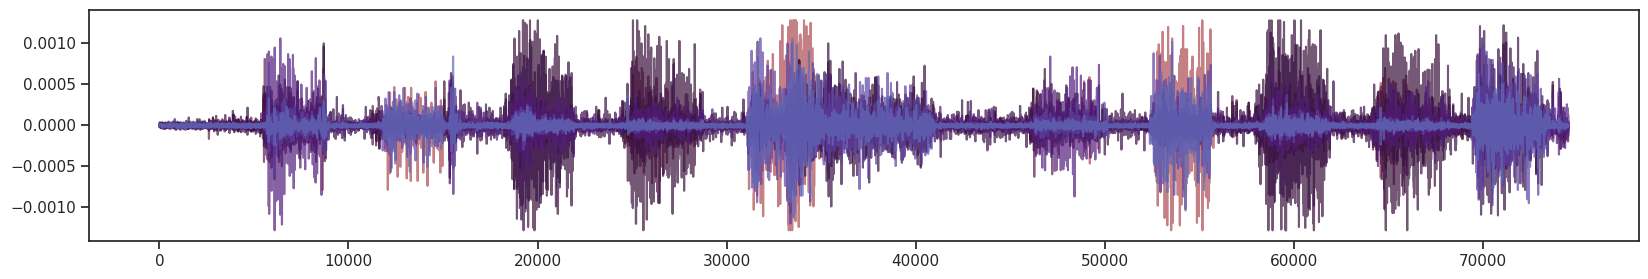

In [12]:
emg_raw_sf = SignalFrame(data_paths[2], 1./1000)
plot_vs_time(emg_raw_sf)
# emg_raw_sf.to_csv('snip_s', ['time', 'channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8',])

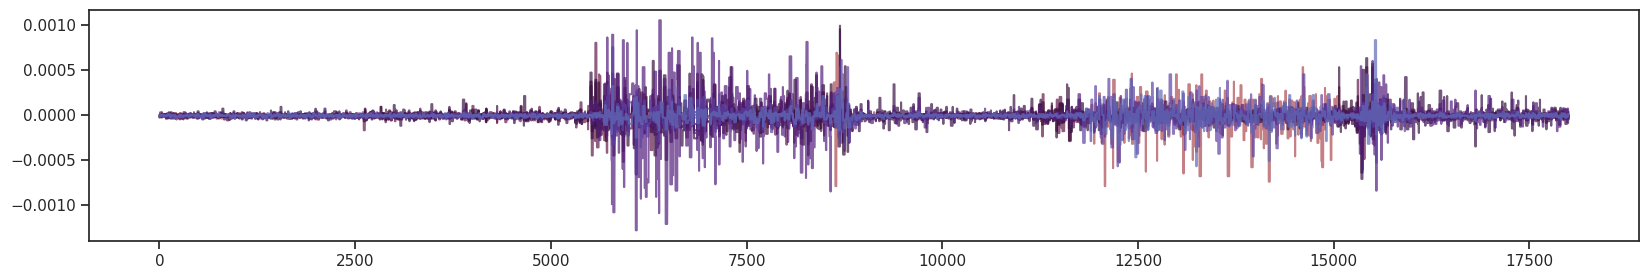

In [13]:
emg_raw_sf = SignalFrame(data_paths[2], 1./1000)
condition = emg_raw_sf.time < 18000
emg_raw_sf.set_signal(emg_raw_sf.time[condition], emg_raw_sf.sample_sets[:, condition], emg_raw_sf.sample_class[condition], emg_raw_sf.sample_period)
plot_vs_time(emg_raw_sf)
emg_raw_sf.to_csv('snip_s', ['time', 'channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8',])

In [24]:
print(f"Peak = {get_peak(emg_total_s)*1000}mV")

Peak = 1.27mV
